# ∂ 05 · Softmax and Cross-Entropy Gradients for Word2Vec

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 5 of 9
> Course notes: pages 11–14 – $E=-\log(y_o)$, $\ \dfrac{\partial E}{\partial u_k}=\dfrac{\partial E}{\partial y_o}\Big(\sum_i\dfrac{\partial y_o}{\partial z_i}\dfrac{\partial z_i}{\partial u_k}\Big)$, the quotient-rule derivation of the softmax, $\ \Delta u_k=\eta(\delta_{ok}-y_k)h^\top$, $\ \Delta v=\eta\big(u_o-\sum_iy_iu_i\big)$

The model from notebook 04 predicts neighbours badly ($E\approx\log n$). To train it we need $\partial E/\partial U$ and $\partial E/\partial V$. This notebook derives them **step by step, following the notes**, checks them numerically, and then reads what they *mean*: the updates have a beautifully simple interpretation.

### 🎯 What you will learn
| # | Result |
|---|---|
| 1 | The softmax derivative $\dfrac{\partial y_o}{\partial z_k}=y_o(\delta_{ok}-y_k)$, via the quotient rule |
| 2 | $\dfrac{\partial E}{\partial z_k}=y_k-\delta_{ok}$ – "prediction minus truth" |
| 3 | Output vectors: $\Delta u_k=\eta\ (\delta_{ok}-y_k)\ h$ – **every** row of $U$ changes |
| 4 | Input vectors: $\Delta v_c=\eta\ \big(u_o-\sum_iy_iu_i\big)$ – **one** column of $V$ changes |
| 5 | Gradient check, and a picture of what one update does |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)

---
## 1 · The variables

### 📖 Notation for the word2vec notebooks (same as the course notes, pages 10–14)

| Symbol | Shape | Meaning |
|---|---|---|
| $n$ | number | vocabulary size: how many different words we know |
| $d$ | number | embedding size: how many numbers describe one word (notes: typically 300) |
| $w_k$ | – | the $k$-th word of the vocabulary, $k=1..n$ |
| $x$ | $n\times1$ | one-hot vector of the **input** word: all zeros except a 1 at its index |
| $V$ | $d\times n$ | **input** matrix. Column $k$, written $v_k$, is the **word vector** of $w_k$ |
| $h=Vx$ | $d\times1$ | hidden vector. Because $x$ is one-hot, $h$ is simply the column $v_c$ of the input word $c$ |
| $U$ | $n\times d$ | **output** matrix. Row $k$, written $u_k$, is the "output vector" of $w_k$ |
| $z=Uh$ | $n\times1$ | one score per vocabulary word: $z_k=u_k\cdot h$ |
| $y=\text{softmax}(z)$ | $n\times1$ | probabilities: $y_k=e^{z_k}/\sum_{m}e^{z_m}$ = predicted chance that $w_k$ is the context word |
| $o$ | index | the **true** output (context) word of this training example |
| $E=-\log y_o$ | number | error: minus the log of the probability given to the right word |
| $\delta_{ok}$ | number | Kronecker delta: 1 if $o=k$, else 0 |
| $\eta$ | number | learning rate |

No biases and no activation function except the final softmax, so the model has exactly $2\ d\ n$ parameters (notes, page 10).
New here: $t$ = the one-hot vector of the true output word ($t_k=\delta_{ok}$), and $e=y-t$, the **prediction error** vector.

---
## 2 · The forward pass for one training pair, as code 💻

For a pair $(c,o)$ – input word $c$, true neighbour $o$:

$$h=v_c,\qquad z=Uh,\qquad y=\text{softmax}(z),\qquad E=-\log y_o$$

We use a tiny model ($n=6$ words, $d=3$) so every number can be printed.

In [2]:
def softmax(z):
    e = np.exp(z - z.max())                 # subtract the max: same result, no overflow
    return e / e.sum()


def forward(V, U, c, o):
    """One skip-gram pair (c → o). Returns h, z, y and the error E."""
    h = V[:, c]                             # h = V x = column c
    z = U @ h                               # z_k = u_k · h
    y = softmax(z)
    return h, z, y, -np.log(y[o])

**A tiny random model and one pair:**

In [3]:
rng = np.random.default_rng(0)
n_toy, d_toy = 6, 3
V = rng.normal(0, 0.5, (d_toy, n_toy))
U = rng.normal(0, 0.5, (n_toy, d_toy))
c, o = 2, 4                                 # input word 2, true neighbour 4
h, z, y, E = forward(V, U, c, o)
print("h =", h.round(3))
print("z =", z.round(3))
print("y =", y.round(3), " (sums to", y.sum().round(6), ")")
print(f"E = -log y_o = -log {y[o]:.3f} = {E:.3f}")

h = [ 0.32  -0.352 -0.623]
z = [-0.077  0.226  0.36  -0.136 -0.075 -0.062]
y = [0.146 0.197 0.226 0.137 0.146 0.148]  (sums to 1.0 )
E = -log y_o = -log 0.146 = 1.924


---
## 3 · The derivation, following the notes ✍️

We need $\dfrac{\partial E}{\partial u_k}$ for every row of $U$, and $\dfrac{\partial E}{\partial v_c}$ for the input column of $V$. Everything goes through the scores $z$, so we first find $\partial E/\partial z_k$.

### Step 1 – derivative of the error with respect to $y_o$

$$E=-\log y_o\qquad\Rightarrow\qquad\frac{\partial E}{\partial y_o}=-\frac{1}{y_o}$$

### Step 2 – derivative of the softmax (the quotient rule, notes page 12)

Write $S=\sum_{m=1}^{n}e^{z_m}$, so $y_o=e^{z_o}\cdot\dfrac1S$. Differentiate the product with respect to $z_k$:

$$\frac{\partial y_o}{\partial z_k}=\frac1S\ \frac{\partial e^{z_o}}{\partial z_k}+e^{z_o}\ \frac{\partial}{\partial z_k}\Big(\frac1S\Big)=\frac1S\ e^{z_o}\frac{\partial z_o}{\partial z_k}+e^{z_o}\Big(-\frac{1}{S^2}\Big)\underbrace{\frac{\partial S}{\partial z_k}}_{e^{z_k}}$$

Now $\dfrac{\partial z_o}{\partial z_k}=\delta_{ok}$ (1 if $o=k$, else 0), and $\dfrac{e^{z_o}}{S}=y_o$, $\dfrac{e^{z_k}}{S}=y_k$:

$$\boxed{\frac{\partial y_o}{\partial z_k}=y_o\ \delta_{ok}-y_o\ y_k=y_o\ (\delta_{ok}-y_k)}$$

### Step 3 – combine: the error signal at the scores

$$\frac{\partial E}{\partial z_k}=\frac{\partial E}{\partial y_o}\cdot\frac{\partial y_o}{\partial z_k}=-\frac1{y_o}\ y_o\ (\delta_{ok}-y_k)=\boxed{\ y_k-\delta_{ok}\ }$$

In vector form $\partial E/\partial z=y-t=e$: **predicted probability minus the truth**, for every word. (The same result as softmax + cross-entropy in module 02.)

### Step 4 – rows of $U$ (output vectors)

$z_k=u_k\cdot h$ depends on row $u_k$ and on no other row, and $\dfrac{\partial z_k}{\partial u_k}=h^\top$. So (notes: the sum over $i$ keeps only the term $i=k$)

$$\frac{\partial E}{\partial u_k}=\sum_i\frac{\partial E}{\partial z_i}\frac{\partial z_i}{\partial u_k}=(y_k-\delta_{ok})\ h^\top\qquad\Rightarrow\qquad\boxed{\Delta u_k=-\eta\frac{\partial E}{\partial u_k}=\eta\ (\delta_{ok}-y_k)\ h^\top}$$

| case | update | meaning (notes page 13) |
|---|---|---|
| $k=o$ (the true word) | $\eta\ (1-y_o)\ h$ | pull $u_o$ **towards** $h$ – more so the less sure we were |
| $k\neq o$ | $-\eta\ y_k\ h$ | push $u_k$ **away** from $h$, in proportion to how much we wrongly predicted it. *"If 'my' has probability 0, no need to change anything."* |

### Step 5 – the input column of $V$ (the word vector)

$h$ affects $E$ through **every** score: $\dfrac{\partial z_k}{\partial h}=u_k$, so

$$\frac{\partial E}{\partial h}=\sum_{k=1}^n(y_k-\delta_{ok})\ u_k=U^\top(y-t)$$

Since $h=Vx=v_c$, only **column $c$** of $V$ influences $h$ (*"k = input → I; k ≠ input → 0"*, notes page 14):

$$\boxed{\Delta v_c=-\eta\ U^\top(y-t)=\eta\Big(u_o-\sum_{i=1}^{n}y_i\ u_i\Big)},\qquad\Delta v_k=0\ \text{ for }k\neq c$$

**Notes' interpretation:** $u_o$ is *"the word I should have predicted"*, and $\sum_iy_iu_i$ is *"each word $i$ predicted with probability $y_i$"* – the **average prediction**. The word vector moves from what the model expected towards what actually happened.

---
## 4 · The gradients in code 💻

### 4.1 · The error signal $e=y-t$

In [4]:
def error_signal(y, o):
    """dE/dz = y - t, where t is the one-hot vector of the true word o."""
    e = y.copy()
    e[o] -= 1.0
    return e

e = error_signal(y, o)
print("y     =", y.round(3))
print("t     =", np.eye(n_toy)[o])
print("e=y-t =", e.round(3), "  (sums to", e.sum().round(10), ")")

y     = [0.146 0.197 0.226 0.137 0.146 0.148]
t     = [0. 0. 0. 0. 1. 0.]
e=y-t = [ 0.146  0.197  0.226  0.137 -0.854  0.148]   (sums to -0.0 )


The entries of $e$ always sum to 0 (probabilities sum to 1, and so does $t$): whatever is added to the true word's score is taken from the others.

📊 **Plot:** $y$, $t$ and $e$ for this pair. Only the true word has a negative error (its score must go **up**); every other word has a positive error equal to its probability (its score must go **down**).

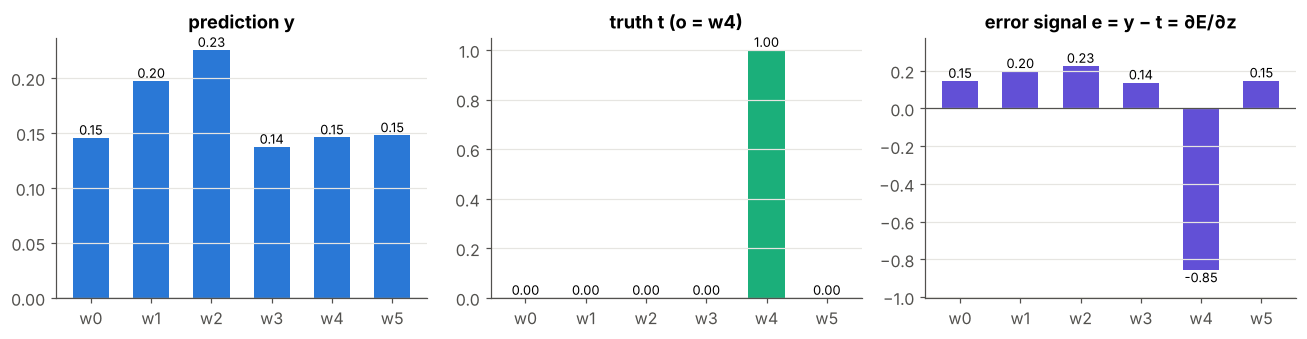

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
words_toy = [f"w{k}" for k in range(n_toy)]
for ax, vals, title, col in [(axs[0], y, "prediction y", C["blue"]), (axs[1], np.eye(n_toy)[o], f"truth t (o = w{o})", C["aqua"]),
                             (axs[2], e, "error signal e = y − t = ∂E/∂z", C["violet"])]:
    bars = ax.bar(words_toy, vals, color=col, width=0.6)
    ax.bar_label(bars, fmt="%.2f", fontsize=8.5); ax.axhline(0, color=C["muted"], lw=0.8)
    ax.set_title(title); ax.grid(axis="x", visible=False)
axs[2].set_ylim(e.min() - 0.15, max(e.max(), 0) + 0.15)
plt.tight_layout(); plt.show()

### 4.2 · All gradients for one pair
* `dU = np.outer(e, h)` → row $k$ is $e_k\ h^\top=(y_k-\delta_{ok})h^\top$ (Step 4) – an $n\times d$ matrix, **all rows non-zero**.
* `dh = U.T @ e` → $U^\top(y-t)$ (Step 5); it goes into column $c$ of a zero matrix shaped like $V$.

In [6]:
def gradients(V, U, c, o):
    """dE/dV and dE/dU for one skip-gram pair (c → o), full softmax."""
    h, z, y, E = forward(V, U, c, o)
    e = error_signal(y, o)                  # dE/dz
    dU = np.outer(e, h)                     # dE/du_k = e_k h^T   (every row)
    dV = np.zeros_like(V)
    dV[:, c] = U.T @ e                      # dE/dv_c = U^T e     (one column only)
    return dV, dU, E

dV, dU, E = gradients(V, U, c, o)
print("non-zero columns of dV:", np.flatnonzero(np.abs(dV).sum(axis=0)), " (only the input word c =", c, ")")
print("non-zero rows of dU   :", np.flatnonzero(np.abs(dU).sum(axis=1)), " (every word)")

non-zero columns of dV: [2]  (only the input word c = 2 )
non-zero rows of dU   : [0 1 2 3 4 5]  (every word)


### 4.3 · Gradient check
Same brute-force check as module 02: nudge each parameter by $\pm\varepsilon$ and measure the change in $E$.

In [7]:
def numerical_grad(f, theta, eps=1e-6):
    g = np.zeros_like(theta)
    for idx in np.ndindex(theta.shape):
        old = theta[idx]
        theta[idx] = old + eps; fp = f()
        theta[idx] = old - eps; fm = f()
        theta[idx] = old
        g[idx] = (fp - fm) / (2 * eps)
    return g


def rel_err(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12)

E_fn = lambda: forward(V, U, c, o)[3]
print(f"dU relative error = {rel_err(dU, numerical_grad(E_fn, U)):.2e}")
print(f"dV relative error = {rel_err(dV, numerical_grad(E_fn, V)):.2e}")

dU relative error = 2.07e-10
dV relative error = 1.03e-10


Both around $10^{-10}$: the derivation is right. ✅

📊 **Plot:** where the gradient lives. $\partial E/\partial V$ (left) is zero except for the input word's column; $\partial E/\partial U$ (right) touches every row.

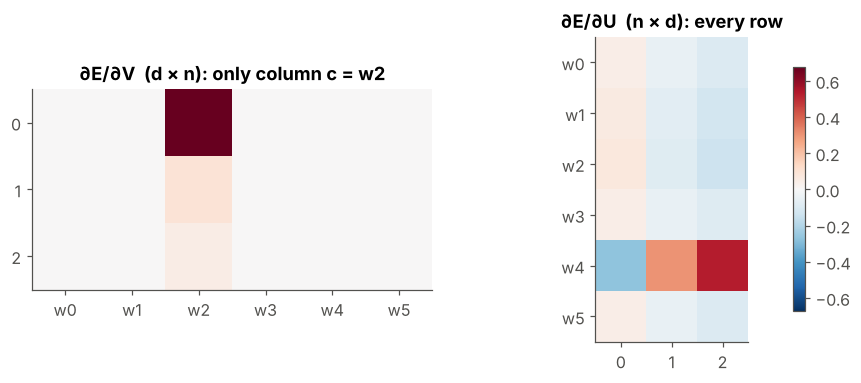

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw=dict(width_ratios=[1.6, 1]))
vmax = max(np.abs(dV).max(), np.abs(dU).max())
axs[0].imshow(dV, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axs[0].set_title(f"∂E/∂V  (d × n): only column c = w{c}"); axs[0].set_xticks(range(n_toy), words_toy); axs[0].set_yticks(range(d_toy))
im = axs[1].imshow(dU, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axs[1].set_title("∂E/∂U  (n × d): every row"); axs[1].set_yticks(range(n_toy), words_toy); axs[1].set_xticks(range(d_toy))
for a in axs: a.grid(False)
plt.colorbar(im, ax=axs, shrink=0.8)
plt.show()

---
## 5 · One update, and what it means geometrically 📐

### 5.1 · Apply one SGD step
$V\leftarrow V-\eta\ \partial E/\partial V$, $\ U\leftarrow U-\eta\ \partial E/\partial U$. The true word's probability should rise and $E$ should fall.

In [9]:
eta = 0.5
V_new, U_new = V - eta * dV, U - eta * dU
_, _, y_new, E_new = forward(V_new, U_new, c, o)
print(f"y_o: {y[o]:.3f} → {y_new[o]:.3f}      E: {E:.3f} → {E_new:.3f}")

y_o: 0.146 → 0.227      E: 1.924 → 1.482


### 5.2 · Check the notes' formula for $\Delta v_c$
$\Delta v_c=\eta\big(u_o-\sum_iy_iu_i\big)$ – "the word I should have predicted minus the average prediction":

In [10]:
expected_u = y @ U                                  # Σ_i y_i u_i  (a d-vector)
delta_vc_notes = eta * (U[o] - expected_u)
print("Δv_c from the gradient :", (V_new[:, c] - V[:, c]).round(4))
print("Δv_c from the notes    :", delta_vc_notes.round(4))

Δv_c from the gradient : [-0.3373 -0.0473 -0.0254]
Δv_c from the notes    : [-0.3373 -0.0473 -0.0254]


### 5.3 · A 2-D picture
With $d=2$ we can draw everything: the output vectors $u_k$ (one per word), the input vector $h=v_c$, and the update. $v_c$ moves along $u_o-\bar u$, from the **average prediction** $\bar u=\sum_iy_iu_i$ towards the **true word** $u_o$; the true word's $u_o$ moves towards $h$, and the others move away from $h$ in proportion to $y_k$.

In [11]:
rng2 = np.random.default_rng(3)
V2 = rng2.normal(0, 0.6, (2, 6)); U2 = rng2.normal(0, 1.0, (6, 2))
c2, o2 = 0, 3
dV2, dU2, _ = gradients(V2, U2, c2, o2)
_, _, y2, _ = forward(V2, U2, c2, o2)
h2 = V2[:, c2]
u_bar = y2 @ U2
print("y =", y2.round(3), "  true word o =", o2)

y = [0.129 0.036 0.196 0.334 0.013 0.292]   true word o = 3


📊 **Plot:** grey = output vectors $u_k$ (true word in green), blue = input vector $h=v_c$ and its update (arrow), orange = the average prediction $\bar u$. Small arrows on each $u_k$ show their updates.

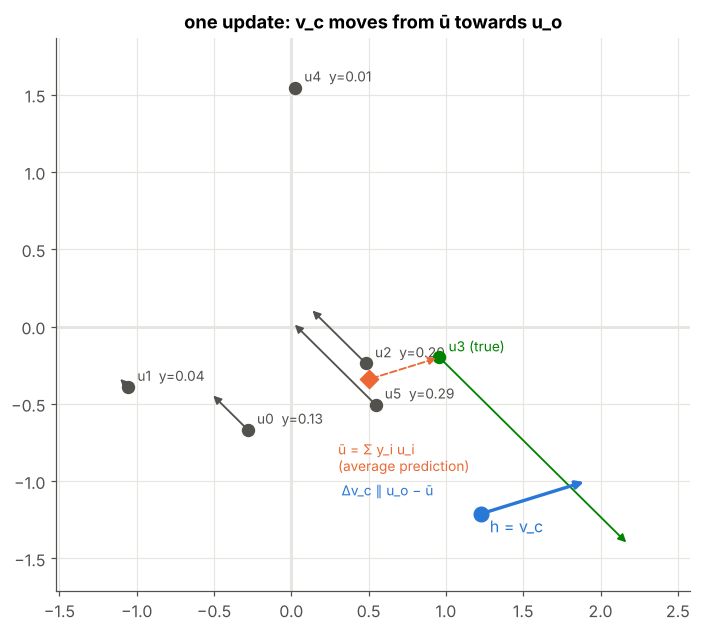

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6))
step = 1.5
for k in range(6):
    col = C["green"] if k == o2 else C["muted"]
    ax.scatter(*U2[k], color=col, s=60, zorder=3)
    ax.annotate(f"u{k}" + (" (true)" if k == o2 else f"  y={y2[k]:.2f}"), U2[k], textcoords="offset points", xytext=(6, 4), color=col, fontsize=9)
    ax.annotate("", xy=U2[k] - step * dU2[k], xytext=U2[k], arrowprops=dict(arrowstyle="-|>", color=col, lw=1.2))
ax.scatter(*h2, color=C["blue"], s=90, zorder=4); ax.annotate("h = v_c", h2, textcoords="offset points", xytext=(6, -12), color=C["blue"])
ax.annotate("", xy=h2 - step * dV2[:, c2], xytext=h2, arrowprops=dict(arrowstyle="-|>", color=C["blue"], lw=2.2))
ax.scatter(*u_bar, color=C["orange"], s=70, marker="D", zorder=4)
ax.annotate("ū = Σ y_i u_i\n(average prediction)", u_bar, textcoords="offset points", xytext=(-20, -60), color=C["orange"], fontsize=9)
ax.annotate("", xy=U2[o2], xytext=u_bar, arrowprops=dict(arrowstyle="-|>", color=C["orange"], lw=1.2, ls="--"))
ax.text(h2[0] - 0.9, h2[1] + 0.12, "Δv_c ∥ u_o − ū", color=C["blue"], fontsize=9)
pts = np.vstack([U2, U2 - step * dU2, h2, h2 - step * dV2[:, c2], u_bar])
ax.set_xlim(pts[:, 0].min() - 0.4, pts[:, 0].max() + 0.4); ax.set_ylim(pts[:, 1].min() - 0.3, pts[:, 1].max() + 0.3)
ax.axhline(0, color=C["grid"]); ax.axvline(0, color=C["grid"]); ax.set_aspect("equal")
ax.set_title("one update: v_c moves from ū towards u_o")
plt.tight_layout(); plt.show()

---
## 6 · How many numbers change per training pair? 🔢

From the boxes above, one skip-gram pair updates:
* **all $n$ rows of $U$** → $n\times d$ numbers;
* **one column of $V$** → $d$ numbers.

The notes (page 14): *"All $d\times n$ update ≈ $3\times10^7$"* for $d=300$, $n=10^5$, *"roughly $10^7$ updates"* per training pair – and a real corpus has billions of pairs. That cost is the subject of notebooks 06–08.

In [13]:
for d_, n_ in [(10, 75), (300, 10_000), (300, 100_000)]:
    print(f"d = {d_:>3}, n = {n_:>7,}:  U updates = {n_ * d_:>12,}   V updates = {d_:>4}   per training pair")

d =  10, n =      75:  U updates =          750   V updates =   10   per training pair
d = 300, n =  10,000:  U updates =    3,000,000   V updates =  300   per training pair
d = 300, n = 100,000:  U updates =   30,000,000   V updates =  300   per training pair


---
## 7 · Summary 📌

| Quantity | Formula | Code |
|---|---|---|
| error signal | $\partial E/\partial z=y-t$ | `e = y.copy(); e[o] -= 1` |
| output vectors | $\Delta u_k=\eta(\delta_{ok}-y_k)h^\top$ | `U -= eta * np.outer(e, h)` |
| input vector | $\Delta v_c=\eta\big(u_o-\sum_iy_iu_i\big)=-\eta U^\top e$ | `V[:, c] -= eta * U.T @ e` |
| other input vectors | $\Delta v_k=0$ | – |
| cost per pair | $nd+d$ numbers | – |

### ✍️ Try it yourself
1. Derive $\partial E/\partial z_k$ for CBOW, where $h=\frac1r\sum_{t}v_{c_t}$. Which columns of $V$ change, and by how much?
2. Show that if $y=t$ exactly (a perfect prediction) every gradient is zero.
3. Make one word's probability $y_k\approx0$. Confirm its row of $U$ barely changes (*"no need to change anything"*).
4. Repeat the SGD step in section 5.1 ten times. How quickly does $y_o$ approach 1?

**Next →** `06 - Naive Training`: train on the whole corpus with these exact updates.